In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
SEX_COLORS = {"M": "#636EFA", "F": "#EF553B"}   # same colors in all graphs

# Make it the default for every px chart that uses color="sex"
px.defaults.color_discrete_map = SEX_COLORS

In [3]:
shark_attacks = pd.read_csv("GSAF5.csv")
display(shark_attacks)

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,Roebuck Bay,Diving,male,M,NaN,...,NaN,"H. Taunton; N. Bartlett, p. 234",ND-0005-RoebuckBay.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0005,ND.0005,6.0,NaN,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,NaN,Pearl diving,Ahmun,M,NaN,...,NaN,"H. Taunton; N. Bartlett, pp. 233-234",ND-0004-Ahmun.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0004,ND.0004,5.0,NaN,NaN
7122,1900-1905,0.0,Unprovoked,USA,North Carolina,Ocracoke Inlet,Swimming,Coast Guard personnel,M,NaN,...,NaN,"F. Schwartz, p.23; C. Creswell, GSAF",ND-0003-Ocracoke_1900-1905.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0003,ND.0003,4.0,NaN,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,NaN,"Panama Bay 8ºN, 79ºW",NaN,Jules Patterson,M,NaN,...,NaN,"The Sun, 10/20/1938",ND-0002-JulesPatterson.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0002,ND.0002,3.0,NaN,NaN


In [4]:
attacks_reduced = shark_attacks.drop(columns=["State","Name",'Time',"Source",'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'])

display(attacks_reduced)

,Date,Year,Type,Country,Location,Activity,Sex,Age,Injury,Fatal Y/N,Species
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft)
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected
...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Roebuck Bay,Diving,M,NaN,FATAL,Y,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,NaN,Pearl diving,M,NaN,FATAL,Y,NaN
7122,1900-1905,0.0,Unprovoked,USA,Ocracoke Inlet,Swimming,M,NaN,FATAL,Y,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,"Panama Bay 8ºN, 79ºW",NaN,M,NaN,FATAL,Y,NaN


In [5]:
without_missing_sex = attacks_reduced.dropna(subset=["Sex","Year"])
display(without_missing_sex)

,Date,Year,Type,Country,Location,Activity,Sex,Age,Injury,Fatal Y/N,Species
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft)
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected
...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Roebuck Bay,Diving,M,NaN,FATAL,Y,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,NaN,Pearl diving,M,NaN,FATAL,Y,NaN
7122,1900-1905,0.0,Unprovoked,USA,Ocracoke Inlet,Swimming,M,NaN,FATAL,Y,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,"Panama Bay 8ºN, 79ºW",NaN,M,NaN,FATAL,Y,NaN


In [6]:
without_missing_sex.columns = (
    without_missing_sex.columns #takes the column names of the DataFrame
    .str.strip() #removes leading and trailing whitespace from the column names
    .str.lower() #converts the column names to lowercase
    .str.replace(" ", "_") #replaces spaces with underscores in the column names
)

print(without_missing_sex.columns.tolist())

['date', 'year', 'type', 'country', 'location', 'activity', 'sex', 'age', 'injury', 'fatal_y/n', 'species']


In [7]:
def fig_decade_trend():
    without_missing_sex["decade"] = (without_missing_sex["year"] // 10 * 10)
    counts = without_missing_sex.groupby("decade").size().reset_index(name="records")
    counts = counts[counts["decade"] >= 1900]
    fig = px.bar(counts, x="decade", y="records")
    fig.update_xaxes(title_text="Decade")
    fig.update_yaxes(title_text="Recorded Attacks")
    return fig

print("Recorded Shark Attacks by Decade")
fig_decade_trend()

Recorded Shark Attacks by Decade


In [8]:
#filtering dataframe, only data since year 2000
without_missing_sex["year"] = pd.to_numeric(without_missing_sex["year"], errors="coerce")

attacks_reduced_2000_onward = without_missing_sex[without_missing_sex["year"] >= 2000].copy()
display(attacks_reduced_2000_onward)

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,03-Feb-2000,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0
2869,01-Feb-2000,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0
2870,Reported 28-Jan-2000,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0
2871,05-Jan-2000,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0


In [9]:
# Create a copy of the original date column to avoid modifying it permanently
# This ensures the code can be run multiple times without errors
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date'].astype(str)
attacks_reduced_2000_onward

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean
0,18th September,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,18th September
1,16th September,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,16th September
2,14th September,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,14th September
3,13th September,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,13th September
4,7th September,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,7th September
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,03-Feb-2000,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,03-Feb-2000
2869,01-Feb-2000,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,01-Feb-2000
2870,Reported 28-Jan-2000,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,Reported 28-Jan-2000
2871,05-Jan-2000,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,05-Jan-2000


In [10]:
# Remove 'Reported ' prefix from dates
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace('Reported ', '')

# Remove ordinal suffixes (st, nd, rd, th) from day numbers
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'(\d+)(st|nd|rd|th)', r'\1', regex=True)

# Replace hyphens between day and month with a space (e.g., "11-Dec" becomes "11 Dec")
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'(\d+)-([A-Za-z]+)', r'\1 \2', regex=True)

# Remove hyphens between month and year with any surrounding spaces
# This handles cases like "Jan-2023", "Jan- 2023", "Jan -2023", "Jan - 2023"
attacks_reduced_2000_onward['date_clean'] = attacks_reduced_2000_onward['date_clean'].str.replace(r'\s*-\s*\s*(\d{4})', r' \1', regex=True)

# Convert to datetime - dayfirst=True ensures dates like "11 Dec 2021" are parsed correctly
attacks_reduced_2000_onward['date'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'], dayfirst=True, errors='coerce')

# Optional: Drop the temporary column if you don't need it
#attacks_reduced_2000_onward = attacks_reduced_2000_onward.drop('date_clean', axis=1)

/var/folders/nh/3s3pvk8j0gxgybrdb2nsc99h0000gp/T/ipykernel_91365/3768258166.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  attacks_reduced_2000_onward['date'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'], dayfirst=True, errors='coerce')


In [11]:
attacks_reduced_2000_onward

,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean
0,1-09-18,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,18 September
1,1-09-16,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,16 September
2,1-09-14,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,14 September
3,1-09-13,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,13 September
4,1-09-07,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,7 September
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000-02-03,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,03 Feb 2000
2869,2000-02-01,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,01 Feb 2000
2870,2000-01-28,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,28 Jan 2000
2871,2000-01-05,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,05 Jan 2000


In [12]:
# Convert the 'date_clean' column to datetime format before using .dt accessor
attacks_reduced_2000_onward['date_clean'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'],dayfirst=True, errors='coerce')

# Now you can safely use .dt.month_name() to extract month names
attacks_reduced_2000_onward['month'] = attacks_reduced_2000_onward['date_clean'].dt.month_name()

attacks_reduced_2000_onward

/var/folders/nh/3s3pvk8j0gxgybrdb2nsc99h0000gp/T/ipykernel_91365/1232677259.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  attacks_reduced_2000_onward['date_clean'] = pd.to_datetime(attacks_reduced_2000_onward['date_clean'],dayfirst=True, errors='coerce')


,date,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,date_clean,month
0,1-09-18,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,1-09-18,September
1,1-09-16,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,1-09-16,September
2,1-09-14,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,1-09-14,September
3,1-09-13,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,1-09-13,September
4,1-09-07,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,1-09-07,September
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000-02-03,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,2000-02-03,February
2869,2000-02-01,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,2000-02-01,February
2870,2000-01-28,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,2000-01-28,January
2871,2000-01-05,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,2000-01-05,January


In [13]:
# Drop the 'date' and 'date_clean' columns
attacks_reduced_2000_onward = attacks_reduced_2000_onward.drop(columns=['date', 'date_clean'])

attacks_reduced_2000_onward

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [14]:
attacks_reduced_2000_onward['sex'] = attacks_reduced_2000_onward['sex'].astype(str)
attacks_reduced_2000_onward

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [15]:
print(attacks_reduced_2000_onward["sex"].unique())

<StringArray>
['M', 'F', 'M ', 'M F', '?', 'F ', ' M', 'm', 'lli']
Length: 9, dtype: str


In [16]:
# Assistant
clean_sex = pd.Series(["M", "F", "M ", "F "," M","m","M F","?","lli"])

# Fixed dictionary syntax: each key must have its own value separated by colon
sex_map = {
    "M": "M",
    "M ": "M",    # Added colon to map "M " to "M"
    "m": "M",     # Added colon to map "m" to "M"
    " M": "M",    # Added colon to map " M" to "M"
    "F": "F",     # Changed "F " to "F" for consistency
    "F ": "F",    # Added mapping for "F " to "F"
    "M F": np.nan,
    "?":np.nan,
    "lli":np.nan
    
    
}

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["sex"] = attacks_reduced_2000_onward["sex"].map(sex_map)

display(attacks_reduced_2000_onward)

,year,type,country,location,activity,sex,age,injury,fatal_y/n,species,decade,month
0,2026.0,Unprovoked,Australia,Sorrento Beach Perth,Swimming,M,63,Body not recovered,Y,Great White Shark 6m (20ft),2020.0,September
1,2026.0,Unprovoked,Canada,Off the coast of Perce Le Bilbo dive site,Diving,M,?,Injuries to chest shoulder and back,N,Great White Shark,2020.0,September
2,2026.0,Unprovoked,Bahamas,Bimini Island,Swimming,F,37,Serious injuries to right ankle,N,Unknown,2020.0,September
3,2026.0,Unprovoked,Australia,Geraldton,Surfing,M,50's,Foot lost in attack,N,Unknown,2020.0,September
4,2026.0,Unprovoked,USA,Honolulu,Surfing,M,24,Scrapes on inside of legs,N,Tiger Shark suspected,2020.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...
2868,2000.0,Unprovoked,NEW ZEALAND,Oreti Beach (reported as the 4th person bitten...,Surfing,M,12,"No injury, wetsuit punctured",N,NaN,2000.0,February
2869,2000.0,Unprovoked,AUSTRALIA,"Point Sinclair, Cactus Beach near Penong",Surfing,M,26,Hand bitten,N,3 m [10'] shark,2000.0,February
2870,2000.0,Watercraft,REUNION,Saint Pierre,Canoe with 3 men onboard sank,M,NaN,FATAL,Y,NaN,2000.0,January
2871,2000.0,Unprovoked,THAILAND,Phang nga Island,Diving,M,35,FATAL,Y,NaN,2000.0,January


In [17]:
print(attacks_reduced_2000_onward["sex"].unique())

<StringArray>
['M', 'F', nan]
Length: 3, dtype: str


In [18]:
attacks_reduced_2000_onward = attacks_reduced_2000_onward.dropna(subset=["sex"])

In [19]:
# Corrected: Remove the 'values' parameter when counting, or use a different numeric column
# This will count the number of rows for each type-sex combination
type_correlation = attacks_reduced_2000_onward.pivot_table(
    index="type",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(type_correlation)

sex,F,M
type,,
Provoked,NaN,2.0
?,NaN,1.0
Invalid,35.0,127.0
Provoked,20.0,203.0
Questionable,4.0,21.0
Sea Disaster,NaN,10.0
UNprovoked,NaN,1.0
Under investigation,1.0,NaN
Unprovoked,453.0,1776.0


In [20]:
print(attacks_reduced_2000_onward["type"].unique())

<StringArray>
[         'Unprovoked',            'Provoked',        'Questionable',
          'UNprovoked',          'unprovoked',           ' Provoked',
          'Watercraft',        'Sea Disaster',                   nan,
                   '?',          'Unverified',             'Invalid',
 'Under investigation']
Length: 13, dtype: str


In [21]:
clean_type = pd.Series(["Provoked", 
                        "Invalid",
                        " Provoked", 
                        "Questionable",
                        "Unprovoked",
                        "UNprovoked",
                        "unprovoked",
                        "?",
                        "Watercraft",
                        "Sea Disaster",
                        "nan",
                        "Unverified",
                        "Invalid"])

# Fixed dictionary syntax: each key must have its own value separated by colon
type_map = {
    "Provoked":"Provoked", 
    "Invalid": np.nan,
    " Provoked":"Provoked", 
    "Questionable":"Unprovoked",
    "Unprovoked":"Unprovoked",
    "UNprovoked":"Unprovoked",
    "unprovoked":"Unprovoked",
    "?": np.nan,
    "Watercraft": np.nan,
    "Sea Disaster": np.nan,
    "nan": np.nan,
    "Unverified": np.nan,
    "Invalid": np.nan
    
    }

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["type"] = attacks_reduced_2000_onward["type"].map(type_map)

print(attacks_reduced_2000_onward["type"].unique())

<StringArray>
['Unprovoked', 'Provoked', nan]
Length: 3, dtype: str


In [22]:
types_correlation = attacks_reduced_2000_onward.pivot_table(
    index="type",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(types_correlation)

sex,F,M
type,,
Provoked,20,205
Unprovoked,457,1799


In [23]:
activities_correlation = attacks_reduced_2000_onward.pivot_table(
    index="activity",
    columns="sex",
    aggfunc="size"  # Use 'size' instead of specifying values and aggfunc='count'
)
display(activities_correlation.assign(total=activities_correlation.sum(axis=1)).sort_values(by='total', ascending=False))

sex,F,M,total
activity,,,
Surfing,74.0,730.0,804.0
Swimming,143.0,289.0,432.0
Spearfishing,7.0,168.0,175.0
Fishing,2.0,151.0,153.0
Snorkeling,55.0,60.0,115.0
...,...,...,...
Attempting to catch a crocodile,NaN,1.0,1.0
Attempting to Kite surf from Egypt to Saudi Arabia,NaN,1.0,1.0
Air Disaster,NaN,1.0,1.0


In [24]:
print(attacks_reduced_2000_onward["activity"].unique())
print(attacks_reduced_2000_onward["activity"].nunique())

<StringArray>
[                                        'Swimming',
                                           'Diving',
                                          'Surfing',
                                     'Spearfishing',
                              'Wading on a sandbar',
                                    'Spearfishiong',
                                          'Fishing',
                      'Operation of Rescue Torpedo',
                                       'Snorkeling',
                                     'Hydrofoiling',
 ...
                              'Conducting research',
                       'Swimming out to porpoises ',
            'Windsurfing, but sitting on his board',
                                 'Surfing / Wading',
            'Attempting to illegally enter the USA',
 'Spearfishing, holding mesh bag with speared fish',
                         'Boogie boarding / wading',
                 'Feeding prawns to captive sharks',
                    'Canoe 

In [25]:
# Calculate totals for each activity
activity_totals = attacks_reduced_2000_onward.groupby('activity').size()

# Create a mapping: activities with count 1 -> "other", otherwise keep original
activity_mapping = {activity: 'other' if count <= 2 else activity 
                    for activity, count in activity_totals.items()}

# Apply the mapping to create a new column or replace the existing one
attacks_reduced_2000_onward['activity'] = attacks_reduced_2000_onward['activity'].map(activity_mapping)

# Now create your pivot table with the updated activities
activities_correlation = attacks_reduced_2000_onward.pivot_table(
    index="activity",
    columns="sex",
    aggfunc="size"
)
display(activities_correlation.assign(total=activities_correlation.sum(axis=1)).sort_values(by='total', ascending=False))

sex,F,M,total
activity,,,
Surfing,74.0,730.0,804.0
Swimming,143.0,289.0,432.0
other,71.0,273.0,344.0
Spearfishing,7.0,168.0,175.0
Fishing,2.0,151.0,153.0
Snorkeling,55.0,60.0,115.0
Wading,48.0,51.0,99.0
Diving,4.0,53.0,57.0
Standing,15.0,34.0,49.0


In [26]:
print(attacks_reduced_2000_onward['activity'].unique().tolist())
print(attacks_reduced_2000_onward['activity'].nunique())

['Swimming', 'Diving', 'Surfing', 'Spearfishing', 'other', 'Fishing', 'Snorkeling', 'Scuba Diving', 'SCUBA Diving', 'Wading', 'Kayaking ', 'Kayaking', 'Bathing', 'Free diving', 'Paddle boarding', 'Scuba diving', 'Kayak fishing', nan, 'Boogie boarding', 'Standing', 'Kite surfing', 'Diving for crayfish', 'Windsurfing', 'Surf skiing ', 'Fishing for sharks', 'Boogie Boarding', 'Playing', 'Canoeing', 'Body boarding', 'Body surfing', 'Body Surfing', 'Surf fishing', 'Treading water', 'Body Boarding', 'Stand-Up Paddleboarding', 'Feeding sharks', 'Fishing ', 'Floating', 'Walking', 'Surf-skiing', 'Surfing ', 'Kayaking / Fishing', 'SUP', 'Sea disaster', 'Kayak Fishing', 'Shark fishing', 'Kite Surfing', 'Swimming ', 'Playing in the surf', 'Wade Fishing', 'Spearfishing (free diving)', 'Sea Disaster', 'Walking out of the water after surfing', 'Jumping', 'Surf skiing', 'Sitting on surfboard']
55


In [27]:
clean_activity = pd.Series(['Swimming',
                            'Diving', 
                            'Surfing', 
                            'Spearfishing', 
                            'other',
                            'Fishing', 
                            'Snorkeling',
                            'Kayaking',
                            'Scuba Diving',
                            'SCUBA Diving',
                            'Wading',
                            'Kayaking ',
                            'Bathing', 
                            'Free diving', 
                            'Paddle boarding',
                            'Scuba diving', 
                            'Kayak fishing',
                            "nan",
                            'Boogie boarding', 
                            'Standing', 
                            'Kite surfing',
                            'Diving for crayfish',
                            'Windsurfing',
                            'Surf skiing ', 
                            'Fishing for sharks',
                            'Boogie Boarding',
                            'Playing',
                            'Canoeing',
                            'Body boarding', 
                            'Body surfing',
                            'Body Surfing', 
                            'Surf fishing',
                            'Treading water', 
                            'Body Boarding',
                            'Stand-Up Paddleboarding',
                            'Feeding sharks',
                            'Fishing ',
                            'Floating',
                            'Walking', 
                            'Surf-skiing', 
                            'Surfing ',
                            'Kayaking / Fishing', 
                            'SUP', 
                            'Sea disaster',
                            'Kayak Fishing', 
                            'Shark fishing',
                            'Kite Surfing', 
                            'Swimming ',
                            'Playing in the surf', 
                            'Wade Fishing', 
                            'Spearfishing (free diving)',
                            'Sea Disaster', 
                            'Walking out of the water after surfing',
                            'Jumping', 
                            'Surf skiing', 
                            'Sitting on surfboard'])

# Fixed dictionary syntax: each key must have its own value separated by colon
activity_map = {'Swimming':"Swimming",
                 'Diving' :"Diving",
                'Surfing':"Surfing", 
                'Spearfishing':"Fishing", 
                'other':"Other",
                'Fishing':"Fishing", 
                'Snorkeling':"Diving",
                'Kayaking':"Kayaking",
                'Scuba Diving':"Diving",
                'SCUBA Diving':"Diving",
                "Wading":"Other",
                'Kayaking ':"Kayaking",
                'Bathing':"Swimming", 
                'Free diving':"Diving", 
                'Paddle boarding':"Other",
                'Scuba diving':"Diving", 
                'Kayak fishing':"Fishing",
                "nan":"Other",
                'Boogie boarding':"Bodyboarding", 
                'Standing':"Other", 
                'Kite surfing':"Surfing",
                'Diving for crayfish':"Diving",
                'Windsurfing':"Surfing",
                'Surf skiing ':"Surfing", 
                'Fishing for sharks':"Fishing",
                'Boogie Boarding':"Bodyboarding",
                'Playing':"Other",
                'Canoeing':"Other",
                'Body boarding':"Bodyboarding", 
                'Body surfing':"Surfing",
                'Body Surfing':"Surfing", 
                'Surf fishing':"Fishing",
                'Treading water':"Other", 
                'Body Boarding':"Bodyboarding",
                'Stand-Up Paddleboarding':"Bodyboarding",
                'Feeding sharks':"Other",
                'Fishing ':"Fishing",
                'Floating':"Other",
                'Walking':"Other", 
                'Surf-skiing':"Kayaking", 
                'Surfing ':"Surfing",
                'Kayaking / Fishing':"Kayaking", 
                'SUP':"Other", 
                'Sea disaster':"Other",
                'Kayak Fishing':"Fishing", 
                'Shark fishing':"Fishing",
                'Kite Surfing':"Surfing", 
                'Swimming ':"Swimming",
                'Playing in the surf':"Surfing", 
                'Wade Fishing':"Fishing", 
                'Spearfishing (free diving)':"Fishing",
                'Sea Disaster':"Other", 
                 'Walking out of the water after surfing':"Surfing",
                'Jumping':"Other", 
                'Surf skiing':"Surfing", 
                'Sitting on surfboard':"Surfing"
    
    }

# Fixed variable name from 'sex' to 'clean_sex'
attacks_reduced_2000_onward["activity"] = attacks_reduced_2000_onward["activity"].map(activity_map)

print(attacks_reduced_2000_onward["activity"].unique())

<StringArray>
[    'Swimming',       'Diving',      'Surfing',      'Fishing',
        'Other',     'Kayaking',            nan, 'Bodyboarding']
Length: 8, dtype: str


In [28]:
activity_vic=attacks_reduced_2000_onward.groupby(['sex','activity']).size().reset_index(name='count')

In [29]:
#import plotly.express as px
#fig=px.bar(activity_vic,x="count",y="activity",color='sex',barmode='group',title="Types of activities")
#fig.show()

In [30]:
def fig_activity_by_sex():
    g = activity_vic
    fig = px.bar(g, x="activity", y="count", color="sex", barmode="group",
                 hover_data={"count": True, "count": ":.1f"})
    fig.update_xaxes(title_text="activity")
    fig.update_yaxes(title_text="Count of Sex's Attacks")
    fig.update_layout(title=dict(text="Comparison of activities during attacks by Sex", x=0.5))
    return fig


fig_activity_by_sex()
        

In [31]:
see_counts=attacks_reduced_2000_onward.groupby(['year','activity',"sex"]).size().reset_index(name='Count')
print(see_counts)

       year      activity sex  Count
0    2000.0  Bodyboarding   F      1
1    2000.0        Diving   F      1
2    2000.0        Diving   M      6
3    2000.0       Fishing   M      5
4    2000.0      Kayaking   M      1
..      ...           ...  ..    ...
300  2026.0         Other   M      9
301  2026.0       Surfing   F      1
302  2026.0       Surfing   M     14
303  2026.0      Swimming   F      9
304  2026.0      Swimming   M      9

[305 rows x 4 columns]


In [32]:
#shark_dataset=attacks_reduced_2000_onward.dropna(subset=["year"])
#shark_dataset['year']=attacks_reduced_2000_onward['year'].astype(int)
#shark_dataset=attacks_reduced_2000_onward[attacks_reduced_2000_onward['year']>2000]
year_vic=attacks_reduced_2000_onward.groupby(['sex','year']).size().reset_index(name='Count')
#print(year_vic)

In [33]:
import plotly.express as px
fig=px.bar(year_vic,x='year',y='Count',color='sex',barmode='group',title='Chart between male and female every year ')
fig.show()

In [44]:
def female_surfing_by_year():
 
    d = attacks_reduced_2000_onward[(attacks_reduced_2000_onward["sex"] == "F") & (attacks_reduced_2000_onward["activity"] == "Surfing")]
    g = d.groupby("year").size().reset_index(name="counts")
    full_years = pd.DataFrame({"year": range(int(d["year"].min()), int(d["year"].max()) + 1)})
    g = full_years.merge(g, on="year", how="left").fillna({"counts": 0})
    g["counts"] = g["counts"].astype(int)
    return g


In [35]:
def fig_female_surfing_trend():
    g = female_surfing_by_year()
    fig = px.line(g, x="year", y="counts", markers=True)
    fig.update_xaxes(title_text="year")
    fig.update_yaxes(title_text="Recorded Attacks")
    fig.update_layout(title=dict(text="Changes in attacks on female surfers", x=0.5))
    return fig

fig_female_surfing_trend()

In [36]:
aus = attacks_reduced_2000_onward[
    attacks_reduced_2000_onward["country"].astype(str).str.strip().str.upper() == "AUSTRALIA"
]
swimming_vic = aus[
    (aus["activity"] == "Swimming") &
    (aus["year"].between(2016, 2022))
].groupby(["sex", "year"]).size().reset_index(name="count")
swimming_vic["year"] = swimming_vic["year"].astype(int)


In [37]:
swimming_vic

,sex,year,count
0,F,2018,4
1,F,2019,1
2,F,2020,2
3,F,2021,1
4,F,2022,1
5,M,2016,1
6,M,2017,2
7,M,2018,2
8,M,2019,2
9,M,2020,1


In [38]:
def au_swimming_trend():
    g = swimming_vic
    fig = px.line(g, x="year", y="count",color="sex", markers=True)
    fig.update_xaxes(title_text="year", dtick=1)
    fig.update_yaxes(title_text="Number of attacks")
    fig.update_layout(title=dict(text="Recorded Attacks on Swimmers in Australia", x=0.5))
    return fig

au_swimming_trend()

In [39]:
import pandas as pd
import plotly.express as px

scraped_gender_stat = [{"label":"2010","value":25,"display":"25 Percent"},{"label":"2011","value":25.8175,"display":"25.8 Percent"},{"label":"2012","value":26.661732249999996,"display":"26.7 Percent"},{"label":"2013","value":27.533570894574993,"display":"27.5 Percent"},{"label":"2014","value":28.433918662827594,"display":"28.4 Percent"},{"label":"2015","value":29.363707803102056,"display":"29.4 Percent"},{"label":"2016","value":30.32390104826349,"display":"30.3 Percent"},{"label":"2017","value":31.315492612541707,"display":"31.3 Percent"},{"label":"2018","value":32.33950922097182,"display":"32.3 Percent"},{"label":"2019","value":33.3970111724976,"display":"33.4 Percent"},{"label":"2020","value":34.48909343783827,"display":"34.5 Percent"},{"label":"2021","value":35.616886793255574,"display":"35.6 Percent"},{"label":"2022","value":36.78155899139504,"display":"36.8 Percent"},{"label":"2023","value":37.984315970413654,"display":"38 Percent"}]

# same table shape as your other charts: year | value
female_surfers_worldwide = pd.DataFrame(scraped_gender_stat)
female_surfers_worldwide["year"] = female_surfers_worldwide["label"].astype(int)
female_surfers_worldwide = female_surfers_worldwide.rename(columns={"value": "percent"})[["year", "percent"]]

print('The amount of female surfers through the years in % worldwide:\nSource: Priyanka Sharma. "Surfing Industry Statistics." Gitnux, 13 Feb 2026, https://gitnux.org/surfing-industry-statistics.')

def fig_female_surfers_worldwide():
    g = female_surfers_worldwide
    fig = px.line(g, x="year", y="percent", markers=True,
                  title="Percentage of Female Surfers Worldwide (2010-2023)")
    fig.update_xaxes(title_text="year", dtick=1)
    fig.update_yaxes(title_text="Female Surfers Worldwide (%)", ticksuffix="%")
    fig.update_traces(hovertemplate="%{x}: %{y:.1f}%<extra></extra>")
    return fig

fig_female_surfers_worldwide()


The amount of female surfers through the years in % worldwide:
Source: Priyanka Sharma. "Surfing Industry Statistics." Gitnux, 13 Feb 2026, https://gitnux.org/surfing-industry-statistics.


In [45]:
import pandas as pd
import plotly.express as px

swimming_participation = pd.read_csv("swimming_participation.csv")
swimming_participation = swimming_participation.drop_duplicates(subset=["sex", "year"])


def au_swimming_participation_trend():
    g = swimming_participation
    fig = px.line(g, x="year", y="participants", color="sex", markers=True)
    fig.update_xaxes(title_text="year", dtick=1)
    fig.update_yaxes(title_text="Adult Swimmers in Australia (thousands)")
    return fig

au_swimming_participation_trend()

In [ ]:
#More women than men swim in Australia, so raw attack counts can't show who is more at risk.
rate = swimming_participation.merge(swimming_vic, on=["sex", "year"], how="left").fillna({"count": 0})

swim_risk = rate.groupby("sex").agg(attacks=("count", "sum"),
                                    swimmers_000=("participants", "mean")).reset_index()
years = rate["year"].nunique()
swim_risk["attacks_per_million_swimmers"] = swim_risk["attacks"] / (swim_risk["swimmers_000"] / 1000) / years
swim_risk


,sex,attacks,swimmers_000,attacks_per_million_swimmers
0,F,9.0,1860.742857,0.690968
1,M,19.0,1452.571429,1.868607


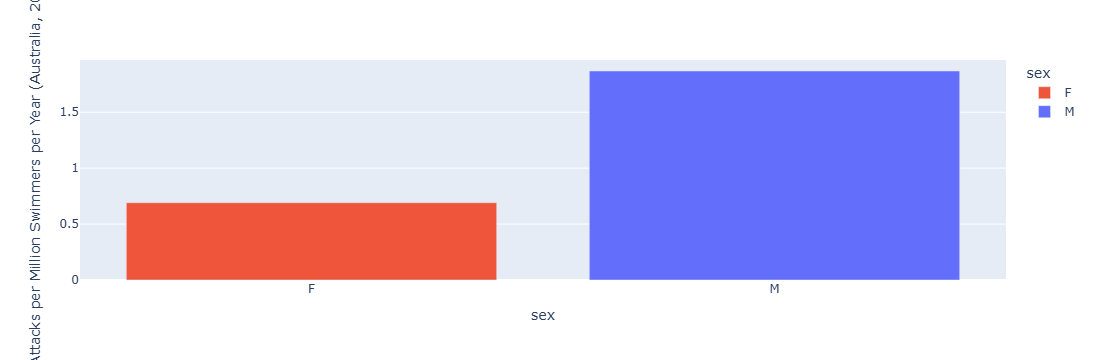

In [ ]:
#Dividing attacks by the number of swimmers gives a fair comparison.
def au_swimming_attack_rate():
    g = swim_risk
    fig = px.bar(g, x="sex", y="attacks_per_million_swimmers", color="sex")
    fig.update_xaxes(title_text="sex")
    fig.update_yaxes(title_text="Shark Attacks per Million Swimmers per Year (Australia, 2016-2022)")
    return fig

au_swimming_attack_rate()


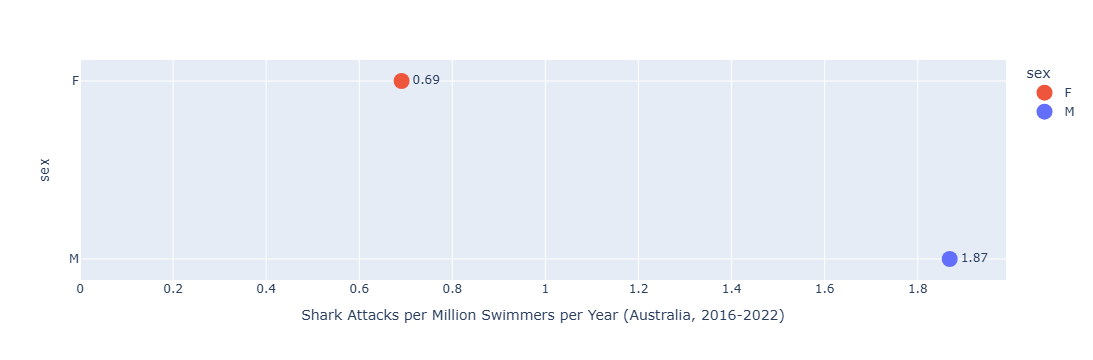

In [ ]:
def au_swimming_attack_rate():
    g = swim_risk
    fig = px.scatter(g, x="attacks_per_million_swimmers", y="sex", color="sex",
                     text=g["attacks_per_million_swimmers"].round(2))
    fig.update_traces(marker=dict(size=16), textposition="middle right")
    fig.update_xaxes(title_text="Shark Attacks per Million Swimmers per Year (Australia, 2016-2022)",
                     rangemode="tozero")
    fig.update_yaxes(title_text="sex")
    return fig

au_swimming_attack_rate()

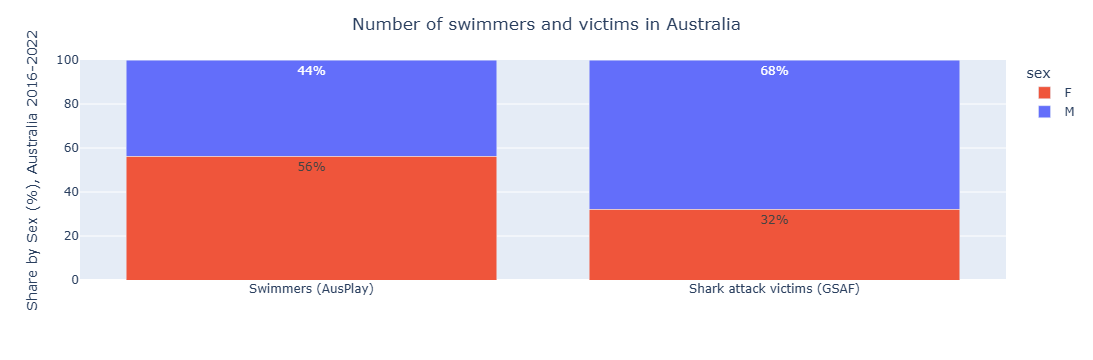

In [ ]:
s = swim_risk.set_index("sex")
share = pd.DataFrame({
    "group": ["Swimmers (AusPlay)"] * 2 + ["Shark attack victims (GSAF)"] * 2,
    "sex":   ["F", "M", "F", "M"],
    "value": [s.loc["F", "swimmers_000"], s.loc["M", "swimmers_000"],
              s.loc["F", "attacks"],      s.loc["M", "attacks"]],
})
share["percent"] = share.groupby("group")["value"].transform(lambda v: v / v.sum() * 100)

def swimmers_vs_victims():
    g = share
    fig = px.bar(g, x="group", y="percent", color="sex",
                 text=g["percent"].round(0).astype(int).astype(str) + "%")
    fig.update_layout(barmode="stack")
    fig.update_xaxes(title_text="")
    fig.update_yaxes(title_text="Share by Sex (%), Australia 2016-2022", range=[0, 100])
    fig.update_layout(title=dict(text="Number of swimmers and victims in Australia", x=0.5))
    return fig

swimmers_vs_victims()

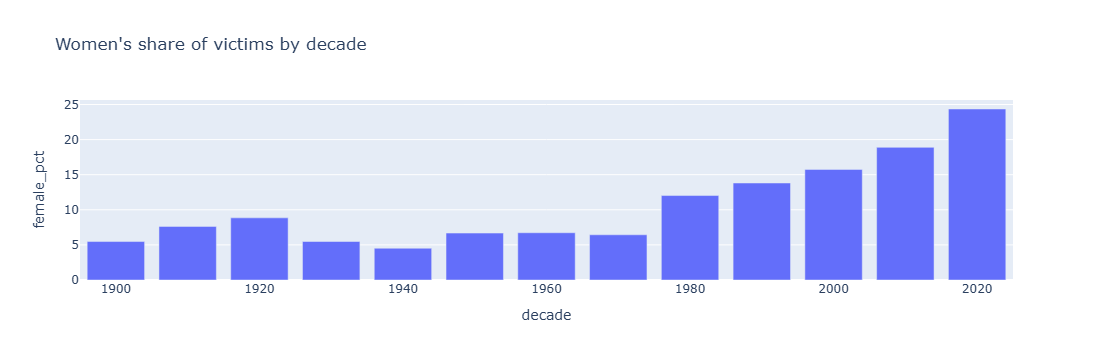

In [ ]:
  d = shark_attacks.copy()
  d["sex"] = d["Sex"].astype(str).str.strip().str.upper()
  d["year"] = pd.to_numeric(d["Year"], errors="coerce")
  d = d[d["sex"].isin(["M", "F"]) & (d["year"] >= 1900)]
  d["decade"] = (d["year"] // 10 * 10).astype(int)
  share = (d.groupby("decade")["sex"].apply(lambda s: (s == "F").mean() * 100)
             .reset_index(name="female_pct"))
  px.bar(share, x="decade", y="female_pct", title="Women's share of victims by decade")

In [ ]:
%run surfing_data.ipynb
surfing

,year,male,female,women_share_%,men_share_%
0,2016,407.2,107.1,20.824422,79.175578
1,2017,384.6,121.6,24.022126,75.977874
2,2018,344.9,135.2,28.160800,71.839200
3,2019,391.6,136.0,25.777104,74.222896
4,2020,407.5,192.7,32.105965,67.894035
5,2021,469.7,254.0,35.097416,64.902584
6,2022,468.1,237.7,33.678096,66.321904
7,2023,463.4,277.7,37.471326,62.528674


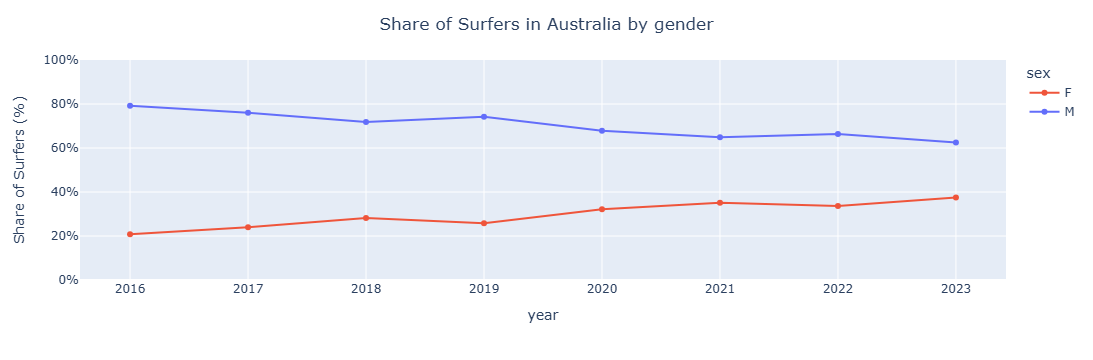

*2023 = July 2022 – June 2023 (no Jan–Dec 2023 table published)


In [ ]:
surfing_long = pd.concat([
    surfing[["year", "women_share_%"]].rename(columns={"women_share_%": "share"}).assign(sex="F"),
    surfing[["year", "men_share_%"]].rename(columns={"men_share_%": "share"}).assign(sex="M"),
]).sort_values(["sex", "year"])

def au_surfing_share_trend():
    g = surfing_long
    fig = px.line(g, x="year", y="share", color="sex", markers=True)
    fig.update_xaxes(title_text="year", dtick=1)
    fig.update_yaxes(title_text="Share of Surfers (%)", range=[0, 100], ticksuffix="%")
    fig.update_layout(title=dict(text="Share of Surfers in Australia by gender", x=0.5))
    return fig

display(au_surfing_share_trend())
print("*2023 = July 2022 – June 2023 (no Jan–Dec 2023 table published)")